<a href="https://colab.research.google.com/github/swarnapatro/AI_KickStart/blob/main/Quantization_Techniques_AWQ_GGUF_GPTQ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧮 Quantization Techniques — Hands-On
### What is quantization, and how do **GPTQ** - Generalized Post-Training Quantization, **AWQ**- Activation-aware Weight Quantization and **GGUF** - GPT-Generated Unified Format, work?

*A beginner-friendly, no-coding-background-needed lab.*

---

## How to use this notebook
1. Run the cells **one by one, top to bottom** (click a cell, press **Shift + Enter**).
2. Every code cell starts with a small banner telling you **what it does, what goes in (INPUT) and what comes out (OUTPUT)**.
3. You do **not** need to understand every line of Python. Read the `# comments` — they explain the idea in plain English.
4. Everything runs on a normal laptop CPU. **No GPU, no big downloads.**

## What you will learn
| # | Topic | Question it answers |
|---|-------|---------------------|
| 1 | What is quantization? | Why do we shrink AI models, and how much memory do we save? |
| 2 | Building blocks | How do we turn decimal numbers into small integers (and back)? |
| 3 | **GGUF** | What is the format behind Ollama / LM Studio / llama.cpp? |
| 4 | A real mini-model | What happens to accuracy when we quantize? |
| 5 | **GPTQ** | How can we round *smartly* and fix our own rounding mistakes? |
| 6 | **AWQ** | How can we protect the weights that matter the most? |
| 7 | Head-to-head | Which method wins at 4, 3 and 2 bits? |
| 8 | Real libraries | How do I do this for a real LLM (reference code)? |

# Part 1 — What is quantization?

### The everyday analogy
Imagine you measure a table with a ruler that has **very fine** markings (to 0.01 mm). The answer is precise, but writing it down takes many digits.
Now measure with a ruler that only has markings every **1 cm**. You write less, remember less, and calculate faster — but every answer is slightly "rounded".

**Quantization = replacing precise numbers (16 or 32 bits each) with rougher numbers (8, 4 or even 2 bits each).**

### Why do we need it?
An AI model (like Llama, Mistral, GPT-style models) is mostly **billions of numbers called *weights*** (also called *parameters*).
* Each weight is normally stored in **16 bits** (FP16/BF16).
* A 7-billion-parameter model → 7,000,000,000 × 16 bits ≈ **14 GB**. That does not fit on many laptops or cheap GPUs.
* If each weight uses only **4 bits**, the same model needs about **3.5 GB**.

| Benefit | Why |
|---|---|
| 💾 Smaller files | fewer bits per weight |
| 🚀 Faster answers | moving less data from memory is usually the bottleneck |
| 💸 Cheaper hardware | a 7B model can run on a laptop |
| ⚠️ Cost | a little accuracy is lost (the "rounding error") |

The whole game of modern quantization (GPTQ, AWQ, GGUF…) is: **lose as little accuracy as possible while using as few bits as possible.**

### Small glossary
| Word | Meaning |
|---|---|
| **Weight / parameter** | one learned number inside the model |
| **Bit** | smallest unit of storage; *n* bits can represent 2ⁿ different values (4 bits → 16 values) |
| **FP32 / FP16** | 32-bit / 16-bit decimal ("floating point") numbers — the "full precision" formats |
| **INT8 / INT4** | 8-bit / 4-bit whole numbers (integers) — the "quantized" formats |
| **Scale** | the number we multiply an integer by to get back to a decimal |
| **Zero-point** | an offset used when the numbers are not centred around 0 |
| **Group size** | how many weights share one scale (smaller group = more accurate, a bit more storage) |
| **Calibration data** | a few sample inputs used to *measure* what matters before quantizing |
| **PTQ** | Post-Training Quantization — shrink an already-trained model (GPTQ, AWQ, GGUF all do this) |

In [ ]:
# CELL 1 - Install / check libraries
# WHAT IT DOES : Installs the 4 small Python libraries this notebook needs (skipped quietly if they
#                are already installed).
# INPUT        : Nothing.
# OUTPUT       : Usually nothing, or a harmless 'you may need to restart the kernel' note. (On
#                Google Colab they are pre-installed.)
# ----------------------------------------------------------------------
%pip install -q --disable-pip-version-check numpy pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# CELL 2 - Imports and global settings
# WHAT IT DOES : Loads the libraries (tools) we will use and sets up a fixed random seed so every
#                student gets identical numbers.
# INPUT        : Nothing.
# OUTPUT       : A confirmation line that the libraries loaded.
# ----------------------------------------------------------------------
import numpy as np                   # NumPy: fast maths on big tables of numbers. A model's "weights" are just NumPy tables (arrays).
import pandas as pd                  # pandas: shows results as neat tables, like an Excel sheet.
import matplotlib.pyplot as plt      # Matplotlib: draws charts so we can SEE the effect of quantization.
from IPython.display import display  # display: prints a pandas table nicely inside the notebook.
from sklearn.datasets import load_digits              # scikit-learn: a small BUILT-IN dataset of 8x8 handwritten-digit images (no internet needed).
from sklearn.model_selection import train_test_split  # splits data into a "training" part and a "testing" part.
from sklearn.neural_network import MLPClassifier      # a small neural network that we will train, then shrink with quantization.



Libraries loaded. NumPy version: 2.1.3


In [ ]:
rng = np.random.default_rng(42)      # Random-number generator with a fixed "seed" (42) -> same random numbers for everyone, every run.
print(rng)
np.set_printoptions(precision=3, suppress=True)       # show NumPy numbers with 3 decimals (easier to read).
pd.options.display.float_format = "{:,.4f}".format    # show table numbers with 4 decimals.
plt.rcParams.update({"figure.figsize": (7.5, 3.8), "axes.grid": True, "grid.alpha": 0.3})  # default chart size and light grid.

print("Libraries loaded. NumPy version:", np.__version__)

Generator(PCG64)
Libraries loaded. NumPy version: 2.1.3


## 1.1 — How much memory does a model need?
Memory needed = *number of weights* × *bits per weight* ÷ 8 (to convert bits into bytes).
Let's calculate it for a **7-billion-parameter** model, which is a common LLM size.

,Format,Bits per weight,Model size (GB),Fits an 8 GB GPU?
0,FP32 (32-bit),32,28.0000,No
1,FP16/BF16 (16-bit),16,14.0000,No
2,INT8 (8-bit),8,7.0000,Yes
3,INT4 (4-bit),4,3.5000,Yes
4,INT3 (3-bit),3,2.6250,Yes
5,INT2 (2-bit),2,1.7500,Yes


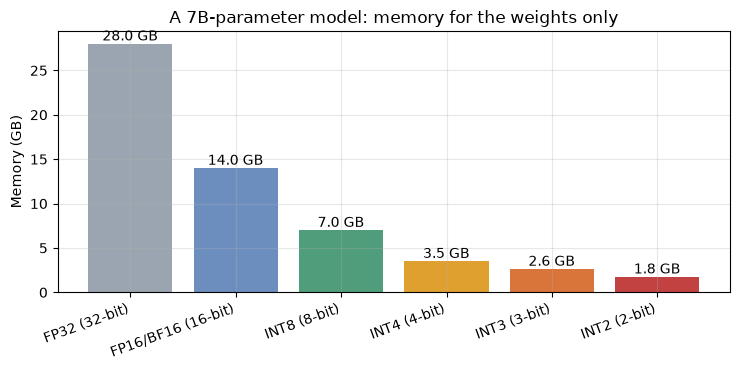

In [ ]:
# CELL 3 - Model size at different precisions
# WHAT IT DOES : Calculates the memory a 7B-parameter model needs at 32, 16, 8, 4, 3 and 2 bits per
#                weight, then draws a bar chart.
# INPUT        : params_billion = 7 (size of the model in billions of weights). You can change it,
#                e.g. to 13 or 70.
# OUTPUT       : A table + bar chart. Expect FP16 = 14 GB and INT4 = 3.5 GB.
# ----------------------------------------------------------------------
params_billion = 7        # <-- try changing to 13 or 70 and re-run!

# Different ways of storing one weight. Key = name, value = bits used for ONE weight.
formats = {"FP32 (32-bit)": 32, "FP16/BF16 (16-bit)": 16, "INT8 (8-bit)": 8,
           "INT4 (4-bit)": 4, "INT3 (3-bit)": 3, "INT2 (2-bit)": 2}

rows = []                                       # we collect one table-row per format
for name, bits in formats.items():
    size_gb = params_billion * 1e9 * bits / 8 / 1e9   # weights x bits / 8 = bytes ; / 1e9 = gigabytes
    rows.append({"Format": name, "Bits per weight": bits, "Model size (GB)": size_gb,
                 "Fits an 8 GB GPU?": "Yes" if size_gb <= 8 else "No"})

mem_df = pd.DataFrame(rows)                     # turn the list of rows into a table
display(mem_df)

fig, ax = plt.subplots()
bars = ax.bar(mem_df["Format"], mem_df["Model size (GB)"],
              color=["#9aa5b1", "#6c8ebf", "#4f9d7a", "#e0a030", "#d9743a", "#c24141"])
ax.bar_label(bars, fmt="%.1f GB")               # write the value on top of each bar
ax.set_ylabel("Memory (GB)")
ax.set_title(f"A {params_billion}B-parameter model: memory for the weights only")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

> **Note:** real memory use is a bit higher (the "KV cache" and activations also need memory), but the weights are the biggest part.

## 1.2 — Quantization by hand (8 numbers)
Before using any clever method, let's do the simplest possible quantization **step by step**, with only 8 weights and **4 bits**:

1. Find the biggest absolute value → `1.27`.
2. 4-bit signed integers go from **−8 to +7**, so the biggest number should map to **7**. → `scale = 1.27 / 7 ≈ 0.181`
3. **Quantize:** divide each weight by `scale` and round to the nearest whole number. (This integer is what we *store*.)
4. **Dequantize:** multiply the integer by `scale` to get an approximate weight back. (This is what the model *uses*.)

In [ ]:
# CELL 4 - Quantize 8 numbers step by step
# WHAT IT DOES : Shows the full quantize -> store -> restore cycle on 8 numbers, and the rounding
#                error of each one.
# INPUT        : weights = 8 decimal numbers, bits = 4.
# OUTPUT       : A table with 4 columns: original | stored integer | restored | error.
# ----------------------------------------------------------------------
weights = np.array([0.12, -0.53, 0.98, -1.27, 0.05, 0.77, -0.31, 0.44])   # INPUT: 8 original weights
bits = 4                                         # we want to store each weight in 4 bits

qmax = 2 ** (bits - 1) - 1                       # largest positive integer for 4-bit signed = 7
scale = np.abs(weights).max() / qmax             # biggest |weight| (1.27) / 7  ->  0.1814   ("how big is one step")
q = np.round(weights / scale).astype(int)        # QUANTIZE: e.g. 0.98 / 0.1814 = 5.4 -> rounds to 5   (stored in 4 bits)
restored = q * scale                             # DEQUANTIZE: e.g. 5 * 0.1814 = 0.907  (approximation of 0.98)

table = pd.DataFrame({"original": weights, "stored integer (4-bit)": q,
                      "restored": restored, "error": weights - restored})
display(table)
print(f"scale (one step size) = {scale:.4f}")
print(f"average absolute error = {np.abs(weights - restored).mean():.4f}   <- the price we pay for using 4 bits")

,original,stored integer (4-bit),restored,error
0,0.1200,1,0.1814,-0.0614
1,-0.5300,-3,-0.5443,0.0143
2,0.9800,5,0.9071,0.0729
3,-1.2700,-7,-1.2700,0.0000
4,0.0500,0,0.0000,0.0500
5,0.7700,4,0.7257,0.0443
6,-0.3100,-2,-0.3629,0.0529
7,0.4400,2,0.3629,0.0771


scale (one step size) = 0.1814
average absolute error = 0.0466   <- the price we pay for using 4 bits


# Part 2 — The building blocks
All modern methods (GPTQ, AWQ, GGUF) are built from the same few ideas. Let's code them once and reuse them everywhere.

| Idea | In plain words |
|---|---|
| **Symmetric** quantization | the integer range is centred on 0 (−8…+7). Good for weights that are balanced around zero. |
| **Asymmetric** quantization | adds a *zero-point* so the range can start anywhere (0…15). Good for one-sided numbers. |
| **Per-tensor** | one single scale for the whole table of weights |
| **Per-group** | a separate scale for each small group (e.g. every 32 weights) → much more accurate |

In [ ]:
# CELL 5 - Core quantization functions (reused in the whole notebook)
# WHAT IT DOES : Defines reusable 'recipes' (functions): quantize_symmetric, quantize_asymmetric,
#                dequantize, fake_quant (round-trip, optionally per group) and error measures.
# INPUT        : A table of weights W (shape rows x columns), number of bits, optional group_size.
# OUTPUT       : No visible output - it only defines the functions. The following cells call them.
# ----------------------------------------------------------------------
def quantize_symmetric(x, bits, axis=None):
    """Symmetric quantization. INPUT: numbers x. OUTPUT: (integers, scale).
    Example: x=[0.5,-1.0], bits=4 -> scale=1/7 -> integers=[4,-7]"""
    qmax = 2 ** (bits - 1) - 1                                   # 4 bits -> 7
    amax = np.max(np.abs(x), axis=axis, keepdims=True)           # biggest |value| (per group if axis is given)
    scale = np.where(amax == 0, 1.0, amax / qmax)                # step size; "where" avoids dividing by zero
    q = np.clip(np.round(x / scale), -qmax - 1, qmax)            # round to integers and keep inside -8..+7
    return q.astype(np.int32), scale

def quantize_asymmetric(x, bits, axis=None):
    """Asymmetric ('zero-point') quantization. INPUT: numbers x. OUTPUT: (integers, scale, zero_point).
    Uses the full range 0..15 for 4 bits, starting at the smallest value."""
    qmax = 2 ** bits - 1                                         # 4 bits -> 15
    xmin = np.min(x, axis=axis, keepdims=True)                   # smallest value
    xmax = np.max(x, axis=axis, keepdims=True)                   # largest value
    scale = np.where(xmax == xmin, 1.0, (xmax - xmin) / qmax)    # step size covering [min, max]
    zero = np.round(-xmin / scale)                               # the integer that represents the real number 0
    q = np.clip(np.round(x / scale) + zero, 0, qmax)             # integers 0..15
    return q.astype(np.int32), scale, zero

def dequantize(q, scale, zero=0):
    """Integers -> approximate decimals. (integer - zero_point) x scale"""
    return (q - zero) * scale

def fake_quant(W, bits, group_size=None, symmetric=True):
    """Quantize then immediately restore ('fake quantization') so we can measure the damage.
    INPUT : W (rows x cols), bits, group_size (None = one scale for the whole table)
    OUTPUT: W_hat, same shape as W, but with rounding error built in."""
    if group_size is None:                                       # per-tensor: one scale for everything
        Wg = W
        axis = None
    else:                                                        # per-group: cut each row into chunks of 'group_size'
        rows, cols = W.shape
        Wg = W.reshape(rows, cols // group_size, group_size)
        axis = -1                                                # compute scale inside every chunk
    if symmetric:
        q, s = quantize_symmetric(Wg, bits, axis)
        What = dequantize(q, s)
    else:
        q, s, z = quantize_asymmetric(Wg, bits, axis)
        What = dequantize(q, s, z)
    return What.reshape(W.shape)

def rel_error(a, b):
    """Relative error in %: how big is the damage compared with the size of the original? (0 = perfect)"""
    return 100 * np.linalg.norm(a - b) / np.linalg.norm(a)

print("Functions defined: quantize_symmetric, quantize_asymmetric, dequantize, fake_quant, rel_error")

Functions defined: quantize_symmetric, quantize_asymmetric, dequantize, fake_quant, rel_error


## 2.1 — Experiment: how does the number of bits change the error?
We create a fake "layer" of weights that looks like a real LLM layer (small numbers around 0, bell-curve shaped), quantize it with 8, 6, 4, 3 and 2 bits and measure the damage.

,bits,different values available,relative error (%)
0,8,256,1.1328
1,6,64,4.6661
2,4,16,20.5886
3,3,8,47.8702
4,2,4,97.8905


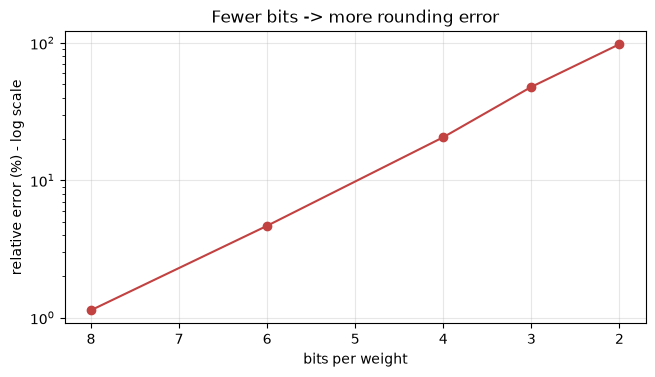

In [ ]:
# CELL 6 - Error vs number of bits
# WHAT IT DOES : Quantizes a 256x256 table of random 'LLM-like' weights using 8/6/4/3/2 bits (one
#                scale for everything) and plots the error.
# INPUT        : W = 65,536 random weights (bell curve, std 0.02). bits = [8, 6, 4, 3, 2].
# OUTPUT       : A table and a chart. Error should grow slowly from 8 to 4 bits and then explode at
#                2-3 bits.
# ----------------------------------------------------------------------
W = rng.normal(0, 0.02, size=(256, 256))        # INPUT: fake layer, 256x256 weights, mostly between -0.06 and +0.06

rows = []
for bits in [8, 6, 4, 3, 2]:
    q, s = quantize_symmetric(W, bits)           # store as integers + one scale
    W_hat = dequantize(q, s)                     # restore to decimals
    rows.append({"bits": bits, "different values available": 2 ** bits,
                 "relative error (%)": rel_error(W, W_hat)})
bits_df = pd.DataFrame(rows)
display(bits_df)

plt.plot(bits_df["bits"], bits_df["relative error (%)"], "o-", color="#c24141")
plt.yscale("log"); plt.gca().invert_xaxis()      # log scale because the error spans a huge range
plt.xlabel("bits per weight"); plt.ylabel("relative error (%) - log scale")
plt.title("Fewer bits -> more rounding error"); plt.show()

## 2.2 — Experiment: symmetric vs asymmetric
If all numbers are **positive** (like the output of a ReLU), a symmetric range wastes half of the integer values on negative numbers that never occur. The zero-point fixes that.

In [ ]:
# CELL 7 - Symmetric vs asymmetric on one-sided data
# WHAT IT DOES : Quantizes all-positive numbers with both methods at 4 bits and compares the error.
# INPUT        : pos = 65,536 random numbers between 0 and 1 (all positive).
# OUTPUT       : Two error values. Asymmetric should be roughly 2x better.
# ----------------------------------------------------------------------
pos = rng.uniform(0, 1, size=(256, 256))         # INPUT: only positive numbers

q, s = quantize_symmetric(pos, 4)                # symmetric: uses only the integers 0..7 (negatives unused)
err_sym = rel_error(pos, dequantize(q, s))

q, s, z = quantize_asymmetric(pos, 4)            # asymmetric: uses all 16 integers 0..15
err_asym = rel_error(pos, dequantize(q, s, z))

print(f"Symmetric  4-bit error: {err_sym:.2f}%   (only ~8 of 16 levels are useful)")
print(f"Asymmetric 4-bit error: {err_asym:.2f}%   (all 16 levels are useful)")

Symmetric  4-bit error: 7.16%   (only ~8 of 16 levels are useful)
Asymmetric 4-bit error: 3.34%   (all 16 levels are useful)


## 2.3 — Experiment: the outlier problem and why *groups* matter
A single huge weight (an **outlier**) forces a big scale, so every *other* weight is rounded very coarsely.
**Fix: give every small group its own scale** (`group_size`). This idea is used by *all* of GPTQ, AWQ and GGUF.

,setting,relative error (%)
0,"no outlier, 1 scale (reference)",20.5886
1,"outlier, 1 scale for all",94.1640
2,"outlier, group size 128",12.1616
3,"outlier, group size 64",10.9730
4,"outlier, group size 32",9.8452


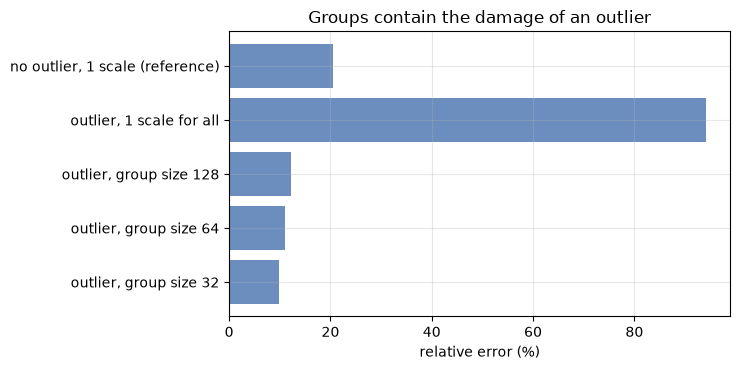

In [ ]:
# CELL 8 - Outliers and group size
# WHAT IT DOES : Plants one outlier in the weights and compares 4-bit error for one scale for
#                everything vs groups of 128, 64, 32.
# INPUT        : W_out = the earlier 256x256 weights with W[0,0] replaced by 0.6 (30 times larger
#                than normal).
# OUTPUT       : A table + bar chart. Smaller groups -> lower error.
# ----------------------------------------------------------------------
W_out = W.copy()
W_out[0, 0] = 0.6                                # INPUT: plant ONE outlier (normal weights are about 0.02)

rows = [{"setting": "no outlier, 1 scale (reference)", "relative error (%)": rel_error(W, fake_quant(W, 4))}]
rows.append({"setting": "outlier, 1 scale for all", "relative error (%)": rel_error(W_out, fake_quant(W_out, 4))})
for g in [128, 64, 32]:                          # smaller and smaller groups
    rows.append({"setting": f"outlier, group size {g}",
                 "relative error (%)": rel_error(W_out, fake_quant(W_out, 4, group_size=g))})
out_df = pd.DataFrame(rows)
display(out_df)

plt.barh(out_df["setting"], out_df["relative error (%)"], color="#6c8ebf")
plt.gca().invert_yaxis(); plt.xlabel("relative error (%)"); plt.title("Groups contain the damage of an outlier")
plt.tight_layout(); plt.show()

# Part 3 — GGUF (the format behind llama.cpp, Ollama and LM Studio)

### What is it?
**GGUF** is a **file format** created by the *llama.cpp* project. One `.gguf` file contains **everything** needed to run a model: the weights, the tokenizer and the settings.
It is designed to run **on ordinary CPUs** (laptops, phones, Raspberry Pi) and can optionally offload layers to a GPU.

> ⚠️ GGUF is the **container**. Inside it, the weights can be stored with many different **quantization types**, e.g. `Q8_0`, `Q5_K_M`, `Q4_K_M`, `Q4_0`, `Q2_K`, … The type is the part that decides size and quality.

### How is it quantized? — **block quantization**
* The weights are cut into small **blocks** (32 weights for the classic `Q4_0/Q8_0` types).
* Every block stores its own **scale** (as a 16-bit number) + the small integers.
* The newer **K-quants** (`Q4_K`, `Q5_K`, `Q6_K`…) use bigger "super-blocks" of 256 weights split into sub-blocks, so the scales themselves are also stored compactly.
* "S / M / L" at the end (e.g. `Q4_K_M`) = Small / Medium / Large **mix**: important tensors get more bits.
* No GPU and no calibration needed for the basic types (an optional *importance matrix, imatrix* can improve quality, using the same idea as GPTQ/AWQ).

### Reading a name: `Q4_K_M`
`Q` = quantized · `4` = about 4 bits · `K` = K-quant (super-blocks) · `M` = medium mix.

| Type | Approx. bits per weight (incl. scales) | Typical use |
|---|---|---|
| `Q8_0` | 8.5 | nearly lossless |
| `Q6_K` | 6.56 | very high quality |
| `Q5_K_M` | ~5.7 | high quality |
| `Q4_K_M` | ~4.9 | **popular sweet spot** |
| `Q4_0` | 4.5 | older, simple 4-bit |
| `Q3_K_M` | ~3.9 | small, some loss |
| `Q2_K` | ~2.6 | tiny, noticeable loss |

Notice "4-bit" really costs **more than 4 bits per weight**, because every block also stores its scale.
Let's rebuild the three classic block types ourselves and *prove* the numbers.

In [ ]:
# CELL 9 - GGUF-style block quantizers (Q8_0, Q4_0, Q4_1)
# WHAT IT DOES : Re-creates, in NumPy, how llama.cpp quantizes blocks of 32 weights (same maths as
#                Q8_0, Q4_0 and Q4_1) and returns the restored weights.
# INPUT        : x = table of blocks, shape (number_of_blocks, 32).
# OUTPUT       : No visible output - it only defines the functions plus the bits-per-weight of each
#                type.
# ----------------------------------------------------------------------
BLOCK = 32                                         # GGUF classic types: 32 weights share one scale

def f16(a):
    """GGUF stores scales as 16-bit decimals; this mimics that tiny rounding."""
    return a.astype(np.float16).astype(np.float32)

def sim_q8_0(x):
    """Q8_0: 8-bit integers (-127..127) + one 16-bit scale per 32 weights."""
    d = f16(np.abs(x).max(axis=1, keepdims=True) / 127.0)           # scale per block
    q = np.round(x / np.where(d == 0, 1, d))                         # integers
    return q * d

def sim_q4_0(x):
    """Q4_0: 4-bit integers (0..15, centred by subtracting 8) + one 16-bit scale per 32 weights."""
    idx = np.abs(x).argmax(axis=1)                                   # position of the biggest |weight| in each block
    biggest = x[np.arange(len(x)), idx][:, None]                     # that weight WITH its sign
    d = biggest / -8.0                                               # scale (llama.cpp trick: sign keeps the full -8..7 range)
    inv = np.where(d == 0, 0.0, 1.0 / np.where(d == 0, 1, d))
    q = np.minimum(15, np.floor(x * inv + 8.5))                      # integers 0..15
    return (q - 8) * f16(d)                                          # restore: (integer - 8) x scale

def sim_q4_1(x):
    """Q4_1: like Q4_0 but also stores the block minimum (a zero-point) -> better for one-sided data."""
    mn = x.min(axis=1, keepdims=True); mx = x.max(axis=1, keepdims=True)
    d = (mx - mn) / 15.0
    inv = np.where(d == 0, 0.0, 1.0 / np.where(d == 0, 1, d))
    q = np.clip(np.round((x - mn) * inv), 0, 15)
    return q * f16(d) + f16(mn)

def gguf_fake_quant(W, kind):
    """Apply one GGUF type to a whole weight table W (rows x cols) block by block."""
    fn = {"Q8_0": sim_q8_0, "Q4_0": sim_q4_0, "Q4_1": sim_q4_1}[kind]
    blocks = W.astype(np.float32).reshape(-1, BLOCK)                 # cut the table into blocks of 32
    return fn(blocks).reshape(W.shape)

# Bits per weight = (bits for 32 integers + bits for the stored scale/min) / 32
BPW = {"Q8_0": (32 * 8 + 16) / 32, "Q4_0": (32 * 4 + 16) / 32, "Q4_1": (32 * 4 + 32) / 32}
print("Bits per weight (including the scales):", BPW)

Bits per weight (including the scales): {'Q8_0': 8.5, 'Q4_0': 4.5, 'Q4_1': 5.0}


In [ ]:
# CELL 10 - Compare the GGUF types on our test weights
# WHAT IT DOES : Quantizes the outlier-containing weights with Q8_0, Q4_0 and Q4_1 and reports the
#                error and the compression vs FP16.
# INPUT        : W_out (256x256 weights containing one outlier) from Part 2.
# OUTPUT       : A table: bits/weight, relative error and compression ratio.
# ----------------------------------------------------------------------
rows = []
for kind in ["Q8_0", "Q4_0", "Q4_1"]:
    W_hat = gguf_fake_quant(W_out, kind)                             # quantize + restore
    rows.append({"GGUF type": kind, "bits per weight": BPW[kind],
                 "relative error (%)": rel_error(W_out, W_hat),
                 "compression vs FP16": 16 / BPW[kind]})
display(pd.DataFrame(rows))
print("Reading the table: Q8_0 is almost lossless; the Q4 types are ~3.2-3.6x smaller than FP16 with a modest error.")

,GGUF type,bits per weight,relative error (%),compression vs FP16
0,Q8_0,8.5000,0.5533,1.8824
1,Q4_0,4.5000,8.7357,3.5556
2,Q4_1,5.0000,7.9057,3.2000


Reading the table: Q8_0 is almost lossless; the Q4 types are ~3.2-3.6x smaller than FP16 with a modest error.


### What does a 4-bit file physically look like?
Computers store whole **bytes** (8 bits). So two 4-bit numbers are **packed into one byte**. Let's do it for one real block of 32 weights.

In [ ]:
# CELL 11 - Pack 4-bit numbers into bytes (what is really saved in the .gguf file)
# WHAT IT DOES : Takes one block of 32 weights, quantizes them to 4-bit integers, packs two integers
#                per byte and unpacks them again to prove nothing is lost.
# INPUT        : One block = the first 32 weights of W.
# OUTPUT       : Byte counts (FP16 = 64 bytes vs Q4_0 = 18 bytes) and a True/False check that
#                packing is lossless.
# ----------------------------------------------------------------------
block = W[0, :BLOCK].astype(np.float32)                 # INPUT: 32 weights (one block)

idx = np.abs(block).argmax()                            # same Q4_0 recipe as before, but written out for ONE block
d = block[idx] / -8.0                                   # scale
ints = np.minimum(15, np.floor(block / d + 8.5)).astype(np.uint8)   # 32 integers, each 0..15 (fits in 4 bits)

low, high = ints[0::2], ints[1::2]                      # even positions / odd positions -> 16 pairs
packed = (low | (high << 4)).astype(np.uint8)           # one byte = [high 4 bits | low 4 bits]
unpacked = np.empty(32, dtype=np.uint8)
unpacked[0::2], unpacked[1::2] = packed & 0x0F, packed >> 4   # reverse the packing

print("First 8 integers   :", ints[:8])
print("First 4 packed bytes:", packed[:4], "(each byte holds TWO 4-bit numbers)")
print(f"Storage FP16 : 32 weights x 2 bytes           = {32 * 2} bytes")
print(f"Storage Q4_0 : {packed.nbytes} bytes of integers + 2 bytes scale = {packed.nbytes + 2} bytes")
print("Packing lossless?", np.array_equal(ints, unpacked))

First 8 integers   : [ 7 12  5  4 15 13  8  9]
First 4 packed bytes: [199  69 223 152] (each byte holds TWO 4-bit numbers)
Storage FP16 : 32 weights x 2 bytes           = 64 bytes
Storage Q4_0 : 16 bytes of integers + 2 bytes scale = 18 bytes
Packing lossless? True


### Using GGUF in real life (summary)
```
Hugging Face model  --convert_hf_to_gguf.py-->  model-f16.gguf  --llama-quantize ... Q4_K_M-->  model-Q4_K_M.gguf
```
Then run it with `llama.cpp`, `Ollama`, `LM Studio` or Python (`llama-cpp-python`). Exact commands are in **Part 8**.

# Part 4 — A real (tiny) neural network to quantize
LLMs are too large for a classroom laptop, so we use a **small neural network that reads handwritten digits** (images of 0–9).
It has the same ingredients as an LLM — layers of weights multiplied with inputs — so the lessons carry over directly.

**Plan:** (1) train the network, (2) measure its accuracy, (3) quantize its weights in different ways, (4) see how much accuracy survives.

In [ ]:
# CELL 12 - Load data and train the network
# WHAT IT DOES : Loads 1,797 handwritten-digit images, splits them into train/test parts, trains a
#                3-layer neural network and prints its accuracy.
# INPUT        : Built-in digits dataset: each image is 8x8 = 64 pixels, label = the digit 0-9.
# OUTPUT       : Shapes of the weight tables and the test accuracy (expect ~97%).
# ----------------------------------------------------------------------
digits = load_digits()                                   # INPUT: images (64 pixel values each) and their correct labels
X = digits.data / 16.0                                   # pixel values are 0..16 -> scale to 0..1 (helps training)
y = digits.target                                        # the correct digit for every image

X_train, X_test, y_train, y_test = train_test_split(     # 70% to learn from, 30% kept hidden to test
    X, y, test_size=0.3, random_state=0, stratify=y)

net = MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=400, random_state=0)   # 64 -> 128 -> 64 -> 10 neurons
net.fit(X_train, y_train)                                # TRAINING: the network learns its weights

coefs = [w.copy() for w in net.coefs_]                   # the learned WEIGHT tables (we will quantize these)
biases = [b.copy() for b in net.intercepts_]             # biases are tiny; we leave them in full precision

print("Weight table shapes (inputs x outputs):", [w.shape for w in coefs])
print("Total number of weights:", sum(w.size for w in coefs))
print(f"Test accuracy of the ORIGINAL model: {net.score(X_test, y_test) * 100:.2f}%")

Weight table shapes (inputs x outputs): [(64, 128), (128, 64), (64, 10)]
Total number of weights: 17024
Test accuracy of the ORIGINAL model: 97.78%


In [ ]:
# CELL 13 - Helper functions to run and score any set of weights
# WHAT IT DOES : Defines forward() (run the network with given weights), evaluate() (accuracy +
#                output error) and quantize_network() (apply any quantization method layer by
#                layer).
# INPUT        : Weight tables, biases and images.
# OUTPUT       : No visible output - defines the functions. It also prints the baseline (full-
#                precision) accuracy.
# ----------------------------------------------------------------------
def forward(weights, biases, X):
    """Run the network by hand. INPUT: weights (list of tables), biases, images X. OUTPUT: raw scores ('logits') for 10 digits."""
    a = X
    for i, (Wt, b) in enumerate(zip(weights, biases)):
        z = a @ Wt + b                                       # '@' = matrix multiplication = the core operation of every AI model
        a = np.maximum(z, 0) if i < len(weights) - 1 else z  # ReLU (negative -> 0) on hidden layers; last layer left raw
    return a

logits_fp = forward(coefs, biases, X_test)                   # reference answers from the full-precision model

def evaluate(weights):
    """Returns (accuracy %, relative error of the output scores vs the original model)."""
    logits = forward(weights, biases, X_test)
    acc = 100 * np.mean(logits.argmax(axis=1) == y_test)     # argmax = the digit with the highest score
    out_err = 100 * np.sum((logits - logits_fp) ** 2) / np.sum(logits_fp ** 2)
    return acc, out_err

def quantize_network(method, bits, group_size, n_calib=256):
    """Quantize every layer with 'method', one layer after another.
    method(W, X, bits, group_size) gets the layer's weights W (outputs x inputs) and calibration inputs X,
    and returns the quantized-then-restored weights."""
    new_weights, a = [], X_train[:n_calib]                   # a = calibration data (256 training images) flowing through the net
    for i, (Wt, b) in enumerate(zip(coefs, biases)):
        W_hat = method(Wt.T, a, bits, group_size)            # .T flips to (outputs x inputs), the layout our functions expect
        new_weights.append(W_hat.T)                          # flip back for the network
        z = a @ W_hat.T + b                                  # push calibration data through the QUANTIZED layer
        a = np.maximum(z, 0) if i < len(coefs) - 1 else z
    return new_weights

acc0, _ = evaluate(coefs)
print(f"Baseline (full precision) accuracy: {acc0:.2f}%")

Baseline (full precision) accuracy: 97.78%


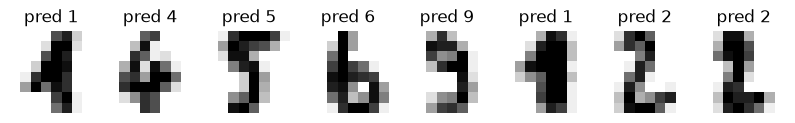

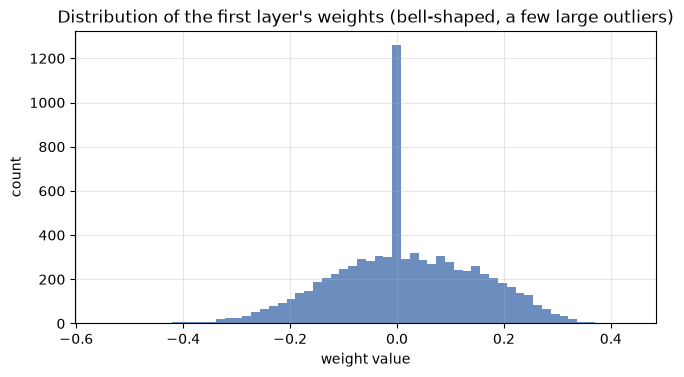

In [ ]:
# CELL 14 - Peek at the data and at what the weights look like
# WHAT IT DOES : Draws 8 test images with the model's prediction, and a histogram of one layer's
#                weights.
# INPUT        : Test images and the first weight table.
# OUTPUT       : A row of digit pictures (title = prediction) and a weight histogram.
# ----------------------------------------------------------------------
fig, axes = plt.subplots(1, 8, figsize=(10, 1.9))
pred = forward(coefs, biases, X_test[:8]).argmax(axis=1)         # model predictions for the first 8 test images
for ax, img, p in zip(axes, X_test[:8], pred):
    ax.imshow(img.reshape(8, 8), cmap="gray_r"); ax.set_title(f"pred {p}"); ax.axis("off")
plt.show()

plt.hist(coefs[0].ravel(), bins=60, color="#6c8ebf")             # .ravel() = flatten the table into one long list
plt.title("Distribution of the first layer's weights (bell-shaped, a few large outliers)")
plt.xlabel("weight value"); plt.ylabel("count"); plt.show()

## 4.1 — Baseline: "Round To Nearest" (RTN)
The simplest post-training quantization: **just round every weight** (what we did by hand in Part 1).
RTN is the **reference point** — GPTQ and AWQ must beat it to be worth the extra effort.
We test per-tensor scale vs. groups of 32 at different bit-widths.

,bits,grouping,accuracy (%),output error (%)
0,8,one scale per layer,97.7778,0.0014
1,8,groups of 32,97.7778,0.0021
2,4,one scale per layer,97.5926,0.8143
3,4,groups of 32,97.4074,0.3373
4,3,one scale per layer,97.5926,2.5861
5,3,groups of 32,97.0370,1.1641
6,2,one scale per layer,75.5556,23.4342
7,2,groups of 32,96.8519,4.2927


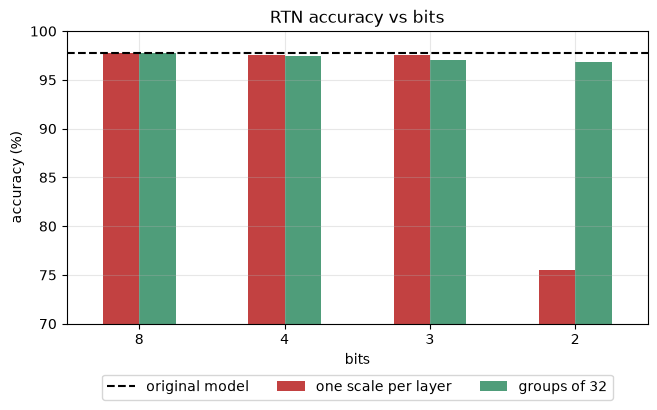

In [ ]:
# CELL 15 - RTN at 8, 4, 3 and 2 bits
# WHAT IT DOES : Quantizes all layers of the network with plain rounding, with and without groups,
#                and measures accuracy.
# INPUT        : bits in [8, 4, 3, 2] and group size in [None (one scale per layer), 32].
# OUTPUT       : A table + chart. Accuracy barely moves (this task is easy) EXCEPT 2-bit with one
#                scale per layer, which collapses. 'Output error' is the more sensitive column: it
#                grows steadily as bits shrink and drops with groups.
# ----------------------------------------------------------------------
def m_rtn(W, X, bits, g):
    """Method 'RTN': plain rounding (asymmetric). Ignores the calibration data X."""
    return fake_quant(W, bits, group_size=g, symmetric=False)

rows = []
for bits in [8, 4, 3, 2]:
    for g in [None, 32]:
        w_q = quantize_network(m_rtn, bits, g)                   # quantize the whole network
        acc, err = evaluate(w_q)                                 # measure the damage
        rows.append({"bits": bits, "grouping": "one scale per layer" if g is None else f"groups of {g}",
                     "accuracy (%)": acc, "output error (%)": err})
rtn_df = pd.DataFrame(rows)
display(rtn_df)

pivot = rtn_df.pivot(index="bits", columns="grouping", values="accuracy (%)").sort_index(ascending=False)
pivot = pivot[["one scale per layer", "groups of 32"]]          # fixed column order -> fixed colours
pivot.plot(kind="bar", color=["#c24141", "#4f9d7a"]); plt.axhline(acc0, color="k", ls="--", label="original model")
plt.ylim(70, 100)                                               # zoom in: the interesting differences are near the top
plt.ylabel("accuracy (%)"); plt.title("RTN accuracy vs bits"); plt.xticks(rotation=0)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3); plt.show()   # legend below the chart so it hides nothing

# Part 5 — GPTQ
*"GPTQ: Accurate Post-Training Quantization for Generative Pre-trained Transformers" (Frantar et al., 2022)*

### The big idea (in one picture)
Plain rounding treats every weight **independently**. But the layer's real job is to produce the right **output** from the inputs. Weights are not independent — if one weight is rounded **up**, a neighbouring weight can be nudged **down** to cancel the mistake.

> 🧾 **Analogy:** You round the prices on a shopping list one by one. After each rounding you look at how far the running total drifted, and adjust the *next* prices a little to bring the total back. At the end the **total** (= the layer output) is almost exact, even though each item was rounded.

### The recipe
1. Run a few sample inputs (**calibration data**, ~128 samples) through the layer.
2. From them compute a table **H** (the *Hessian*, `H = 2·XᵀX`) that tells how much each pair of weights influences the output.
3. Quantize the weights **one column at a time**. After quantizing a column, measure its error and **spread that error over the not-yet-quantized columns** (using the inverse of H) so they compensate.
4. Repeat until every column is done. Scales are computed per group (e.g. 128 weights).

| Property | GPTQ |
|---|---|
| Needs calibration data? | **Yes** (a few hundred samples) |
| Changes the weights beyond rounding? | **Yes** — updates remaining weights to compensate |
| Main target hardware | **GPU** (fast kernels such as Marlin / ExLlama) |
| Typical settings | 4-bit (also 3 / 8), group size 128 |
| Output format | `.safetensors` (Hugging Face) |

In [ ]:
# CELL 16 - A compact GPTQ implementation
# WHAT IT DOES : Implements the GPTQ algorithm in about 25 lines of NumPy: compute H, then quantize
#                column by column while compensating the error.
# INPUT        : W = layer weights (outputs x inputs), X = calibration inputs (samples x inputs),
#                bits, group_size.
# OUTPUT       : No visible output - defines gptq_quantize(), which returns the quantized-then-
#                restored weights.
# ----------------------------------------------------------------------
def gptq_quantize(W, X, bits=4, group_size=32, damp=0.01):
    W = W.astype(np.float64).copy()                      # working copy - will be modified as errors are pushed forward
    out_f, in_f = W.shape
    H = 2.0 * (X.T @ X) / X.shape[0]                     # H: how strongly input columns i and j act together (in_f x in_f)

    dead = np.diag(H) == 0                               # inputs that are ALWAYS zero (e.g. blank image borders)
    H[dead, dead] = 1.0                                  # avoid division by zero for them
    W[:, dead] = 0.0                                     # their weights do not matter at all
    H += damp * np.mean(np.diag(H)) * np.eye(in_f)       # 'damping': small safety value added to the diagonal (numerical stability)

    Hinv = np.linalg.inv(H)                              # inverse of H = tells how to spread the error
    Hinv = np.linalg.cholesky(Hinv).T                    # triangular 'square-root' form of the inverse (standard GPTQ trick)

    Q = np.zeros_like(W)                                 # will hold the final quantized-then-restored weights
    qmax = 2 ** bits - 1
    for i in range(in_f):                                # go through the columns, one at a time
        if i % group_size == 0:                          # start of a new group -> compute its scale / zero-point
            _, scale, zero = quantize_asymmetric(W[:, i:i + group_size], bits, axis=-1)   # shapes (out_f, 1)
        w = W[:, i]                                      # current column (already includes earlier corrections)
        q = np.clip(np.round(w[:, None] / scale) + zero, 0, qmax)         # round this column to integers
        q = ((q - zero) * scale)[:, 0]                   # restore to decimals
        Q[:, i] = q
        err = (w - q) / Hinv[i, i]                       # the rounding mistake of this column (scaled)
        W[:, i + 1:] -= np.outer(err, Hinv[i, i + 1:])   # *** THE GPTQ TRICK: push the mistake onto the remaining columns ***
    return Q

print("gptq_quantize() ready.")

gptq_quantize() ready.


### Test 1 — one layer, GPTQ vs plain rounding
We take the **first layer** of our network and quantize it at 4 and 3 bits with both methods.
We measure the error of the layer's **output** (`X·Wᵀ`) — that is what GPTQ tries to protect, not the error of the weights themselves.

,bits,method,weight error (%),"layer-output error, calibration (%)","layer-output error, unseen test (%)"
0,4,RTN,7.2447,0.2914,0.2931
1,4,GPTQ,14.5598,0.0434,0.0502
2,3,RTN,15.4687,1.1786,1.1820
3,3,GPTQ,23.3445,0.2076,0.2363


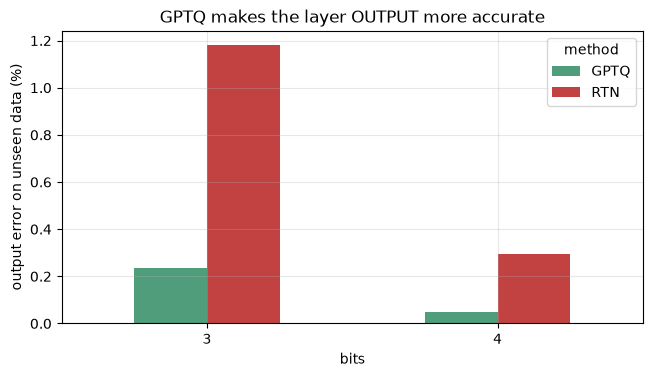

In [ ]:
# CELL 17 - GPTQ vs RTN on a single layer
# WHAT IT DOES : Quantizes the first layer with RTN and GPTQ, then compares the layer-output error
#                on calibration images and on unseen test images.
# INPUT        : W1 = first weight table (128 x 64). Calibration = 256 training images. Test =
#                unseen test images.
# OUTPUT       : A table + chart. GPTQ should have a clearly smaller output error than RTN (even
#                though its WEIGHT error can be larger!).
# ----------------------------------------------------------------------
W1 = coefs[0].T                                         # first layer, layout (outputs=128, inputs=64)
X_cal = X_train[:256]                                   # CALIBRATION data: 256 images used to build H
rows = []
for bits in [4, 3]:
    W_rtn = fake_quant(W1, bits, group_size=32, symmetric=False)     # plain rounding
    W_gptq = gptq_quantize(W1, X_cal, bits=bits, group_size=32)      # GPTQ
    for name, Wq in [("RTN", W_rtn), ("GPTQ", W_gptq)]:
        out_err_cal = 100 * np.sum((X_cal @ (W1 - Wq).T) ** 2) / np.sum((X_cal @ W1.T) ** 2)    # error on calibration data
        out_err_test = 100 * np.sum((X_test @ (W1 - Wq).T) ** 2) / np.sum((X_test @ W1.T) ** 2) # error on UNSEEN data
        rows.append({"bits": bits, "method": name, "weight error (%)": rel_error(W1, Wq),
                     "layer-output error, calibration (%)": out_err_cal,
                     "layer-output error, unseen test (%)": out_err_test})
gptq_df = pd.DataFrame(rows)
display(gptq_df)

piv = gptq_df.pivot(index="bits", columns="method", values="layer-output error, unseen test (%)")
piv.plot(kind="bar", color=["#4f9d7a", "#c24141"]); plt.ylabel("output error on unseen data (%)")
plt.title("GPTQ makes the layer OUTPUT more accurate"); plt.xticks(rotation=0); plt.show()

**Look carefully at the table:** GPTQ's *weight* error can be equal or even **larger** than RTN — yet the *output* error is much **smaller**. That is the whole point: GPTQ doesn't care about each weight being close, it cares about the **result** being close.

# Part 6 — AWQ
*"AWQ: Activation-aware Weight Quantization for LLM Compression and Acceleration" (Lin et al., MIT, 2023)*

### The big idea
**Not all weights are equally important.** Roughly **1 % of the weights** matter far more than the rest — namely the ones that multiply **large input values** (large *activations*). Rounding errors on those weights get *amplified*.

AWQ's insight: look at the **activations** (the data flowing through), not at the weights, to find which channels are important.

### The trick: scale up before rounding
For an important input channel *j*:
* multiply its weights by a factor `s_j > 1` **before** quantizing → the same rounding step is now small *relative* to the weight → less relative error;
* divide the incoming activation by `s_j` so the maths gives **exactly the same result** (in full precision):

`(x / s) · (W × s) = x · W`

> 🎚️ **Analogy:** a band recording. Boost the quiet-but-important instrument before it goes through a noisy channel, then lower it back at playback. The noise hurts it much less.

### The recipe
1. Run calibration data → measure the average magnitude of each input channel (`act_mag`).
2. Try scales `s = act_mag ^ α` for several α between 0 and 1 (α = 0 means "no scaling" = plain RTN).
3. For every α: scale, quantize, un-scale, measure the output error. **Keep the best α.**

| Property | AWQ |
|---|---|
| Needs calibration data? | **Yes**, but only a small amount (it only measures activation sizes, so it overfits less than GPTQ) |
| Changes the weights beyond rounding? | No — only a smart per-channel scaling, then plain rounding |
| Main target hardware | **GPU** (fast 4-bit kernels, vLLM / TGI support) |
| Typical settings | 4-bit, group size 128 |
| Strength | very good accuracy, quantizes quickly |

In [ ]:
# CELL 18 - A compact AWQ implementation
# WHAT IT DOES : Implements the AWQ search: try several scaling strengths alpha, quantize, and keep
#                the one with the smallest output error.
# INPUT        : W = layer weights (outputs x inputs), X = calibration inputs, bits, group_size.
# OUTPUT       : No visible output - defines awq_quantize(), which returns (restored weights, info
#                dictionary with the search history).
# ----------------------------------------------------------------------
def awq_quantize(W, X, bits=4, group_size=32, n_grid=20, symmetric=False):
    X = X.astype(np.float64)
    act_mag = np.abs(X).mean(axis=0)                             # average size of each input channel (shape: in_f) = its 'importance'
    act_mag = np.maximum(act_mag, 1e-3 * act_mag.max())          # avoid extreme/zero values for dead channels
    reference = X @ W.T                                          # the output we want to reproduce (full precision)

    best_err, best_W, best_alpha, history = np.inf, None, 0.0, []
    for k in range(n_grid + 1):                                  # try alpha = 0.00, 0.05, ... 1.00
        alpha = k / n_grid
        s = act_mag ** alpha                                     # important channels (large activation) get larger s
        s = s / np.sqrt(s.max() * s.min())                       # normalise so s stays around 1
        W_hat = fake_quant(W * s[None, :], bits, group_size, symmetric) / s[None, :]   # scale UP -> round -> scale back DOWN
        err = np.mean((X @ W_hat.T - reference) ** 2)            # error of the layer OUTPUT
        history.append((alpha, err))
        if err < best_err:                                       # remember the best alpha
            best_err, best_W, best_alpha = err, W_hat, alpha
    return best_W, {"best_alpha": best_alpha, "history": history}

print("awq_quantize() ready.")

awq_quantize() ready.


### Test 1 — the maths trick really is "free"
Before quantizing, check the claim that scaling the weights up and the activations down gives the **same** answer.

In [ ]:
# CELL 19 - Check: scaling weights up and activations down changes nothing
# WHAT IT DOES : Multiplies the weights by s and divides the inputs by s, then verifies the layer
#                output is identical.
# INPUT        : Random inputs x (5 samples x 8 channels), random weights (4 x 8), random scales s.
# OUTPUT       : True if both ways give the same numbers.
# ----------------------------------------------------------------------
x_demo = rng.normal(size=(5, 8))                        # 5 sample inputs, 8 channels each
w_demo = rng.normal(size=(4, 8))                        # a tiny layer: 8 inputs -> 4 outputs
s_demo = rng.uniform(0.5, 4, size=8)                    # one scale factor per input channel

out_normal = x_demo @ w_demo.T                          # ordinary layer output
out_scaled = (x_demo / s_demo) @ (w_demo * s_demo).T    # inputs divided by s, weights multiplied by s
print("Same result with scaling?", np.allclose(out_normal, out_scaled))

Same result with scaling? True


### Test 2 — a layer with "LLM-like" outlier channels
Real LLMs have a few input channels with **huge activations** (this is well documented). We build a synthetic layer with exactly that:
256 input channels, of which **4 channels are 30× larger** than the others.

,bits,RTN output error (%),AWQ output error (%),best alpha chosen
0,4,0.7719,0.1888,0.3500
1,3,3.8727,0.8823,0.4000


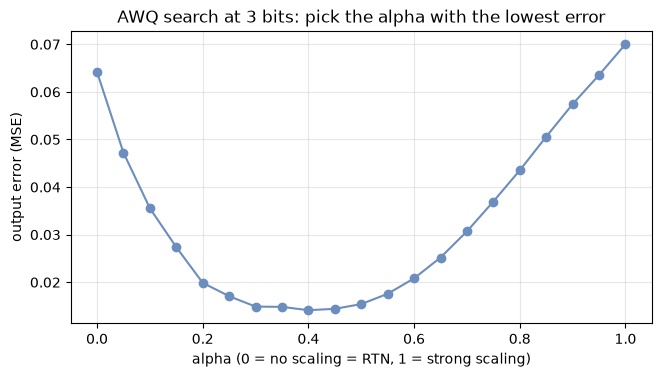

In [ ]:
# CELL 20 - AWQ vs RTN on a layer with outlier activations
# WHAT IT DOES : Builds a synthetic layer with 4 'loud' channels, quantizes it with RTN and AWQ at 4
#                and 3 bits, and plots how the error depends on alpha.
# INPUT        : X_syn = 512 samples x 256 channels (4 of them 30x bigger). W_syn = 128 x 256 random
#                weights.
# OUTPUT       : A table (RTN vs AWQ error on UNSEEN data) and a U-shaped curve: error vs alpha.
# ----------------------------------------------------------------------
in_f, out_f = 256, 128
gain = np.ones(in_f); gain[[10, 77, 130, 201]] = 30.0   # 4 'loud' channels (30x larger activations)
W_syn = rng.normal(0, 0.02, size=(out_f, in_f))          # layer weights
X_syn = rng.normal(size=(512, in_f)) * gain              # calibration inputs
X_new = rng.normal(size=(512, in_f)) * gain              # separate, UNSEEN inputs for a fair test

def out_error(Wq, X):
    return 100 * np.sum((X @ (W_syn - Wq).T) ** 2) / np.sum((X @ W_syn.T) ** 2)

rows = []
for bits in [4, 3]:
    W_rtn = fake_quant(W_syn, bits, group_size=64, symmetric=False)
    W_awq, info = awq_quantize(W_syn, X_syn, bits=bits, group_size=64)
    rows.append({"bits": bits, "RTN output error (%)": out_error(W_rtn, X_new),
                 "AWQ output error (%)": out_error(W_awq, X_new), "best alpha chosen": info["best_alpha"]})
display(pd.DataFrame(rows))

hist = np.array(info["history"])                         # search history of the last run (3-bit)
plt.plot(hist[:, 0], hist[:, 1], "o-", color="#6c8ebf")
plt.xlabel("alpha (0 = no scaling = RTN, 1 = strong scaling)"); plt.ylabel("output error (MSE)")
plt.title("AWQ search at 3 bits: pick the alpha with the lowest error"); plt.show()

### Test 3 — the experiment that inspired AWQ: "protect 1 % of the weights"
What if we simply **kept 1 % of the input channels in full precision** and quantized the rest? Which 1 % should we pick?
* random channels?
* channels with the biggest **weights**?
* channels with the biggest **activations** (the AWQ idea)?

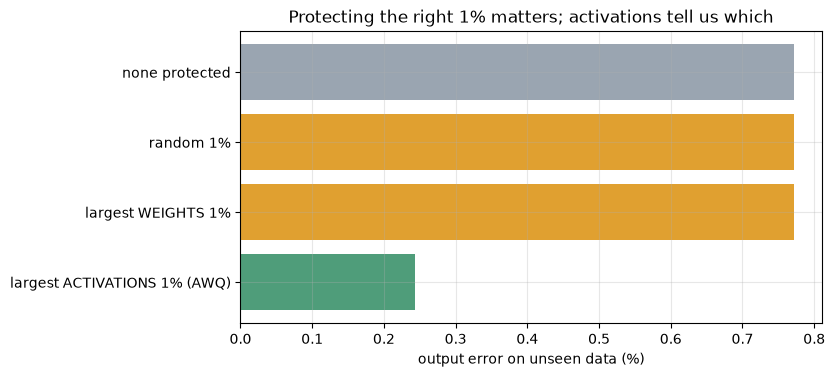

none protected                   ->   0.77%
random 1%                        ->   0.77%
largest WEIGHTS 1%               ->   0.77%
largest ACTIVATIONS 1% (AWQ)     ->   0.24%


In [ ]:
# CELL 21 - Which 1% of channels deserve protection?
# WHAT IT DOES : Keeps 1% (3 of 256) channels in full precision using three different selection
#                rules and compares the resulting output error.
# INPUT        : Same synthetic layer as before; 4-bit RTN with groups of 64.
# OUTPUT       : A bar chart: error after protecting random / largest-weight / largest-activation
#                channels.
# ----------------------------------------------------------------------
bits, g, n_keep = 4, 64, 3                               # keep 3 of 256 channels (about 1%)
W_q = fake_quant(W_syn, bits, g, symmetric=False)        # everything quantized (baseline)

choices = {
    "none protected":              np.array([], dtype=int),
    "random 1%":                   rng.choice(in_f, n_keep, replace=False),
    "largest WEIGHTS 1%":          np.argsort(np.abs(W_syn).mean(axis=0))[-n_keep:],
    "largest ACTIVATIONS 1% (AWQ)": np.argsort(np.abs(X_syn).mean(axis=0))[-n_keep:]}

names, errs = [], []
for name, cols in choices.items():
    W_mix = W_q.copy()
    W_mix[:, cols] = W_syn[:, cols]                      # put the ORIGINAL full-precision weights back for the chosen channels
    names.append(name); errs.append(out_error(W_mix, X_new))

plt.barh(names, errs, color=["#9aa5b1", "#e0a030", "#e0a030", "#4f9d7a"]); plt.gca().invert_yaxis()
plt.xlabel("output error on unseen data (%)"); plt.title("Protecting the right 1% matters; activations tell us which"); plt.show()
for n, e in zip(names, errs): print(f"{n:<32} -> {e:6.2f}%")

AWQ gets (most of) this benefit **without** keeping any weight in 16-bit: scaling is a clean trick that keeps the whole tensor in plain 4-bit, which GPUs can compute efficiently.

# Part 7 — Head-to-head on our neural network
Now we run **everything** on the full network, quantizing all 3 layers, and compare:

* **RTN** (baseline rounding, groups of 32)
* **GPTQ** (error-compensating)
* **AWQ** (activation-aware scaling)
* **GGUF-style** `Q8_0`, `Q4_0`, `Q4_1` (blocks of 32, no calibration needed)

*Calibration data = 256 training images; evaluation = unseen test images.*

,method,bits,bits/weight (with scales),accuracy (%),output error (%)
0,GGUF Q8_0,8,8.5000,97.5926,0.0018
1,GPTQ,4,4.6250,97.5926,0.0274
2,AWQ,4,4.6250,97.4074,0.1852
3,GGUF Q4_0,4,4.5000,97.5926,0.2614
4,RTN,4,4.6250,97.4074,0.3373
5,GGUF Q4_1,4,5.0000,97.7778,0.3529
6,GPTQ,3,3.5938,97.5926,0.2035
7,AWQ,3,3.5938,97.0370,0.5853
8,RTN,3,3.5938,97.0370,1.1641
9,GPTQ,2,2.5625,97.5926,1.2152


Original full-precision accuracy: 97.78%


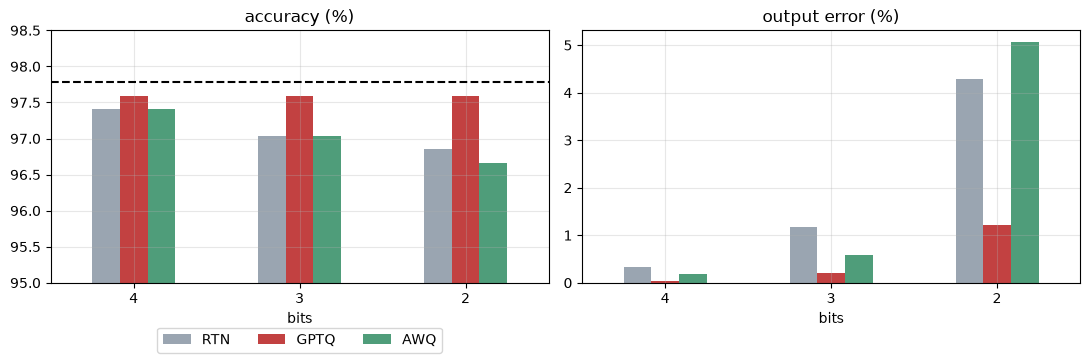

In [ ]:
# CELL 22 - Run all methods at 4, 3 and 2 bits
# WHAT IT DOES : Quantizes the whole network with RTN, GPTQ and AWQ at 4/3/2 bits, and with GGUF-
#                style Q8_0/Q4_0/Q4_1, then reports accuracy and output error.
# INPUT        : Trained network, 256 calibration images, 1,000+ unseen test images.
# OUTPUT       : One results table (sorted by bits; lower 'output error' is better) and two bar
#                charts (accuracy, output error).
# ----------------------------------------------------------------------
def m_gptq(W, X, bits, g): return gptq_quantize(W, X, bits=bits, group_size=g)      # wrapper so all methods share one signature
def m_awq(W, X, bits, g):  return awq_quantize(W, X, bits=bits, group_size=g)[0]
def m_gguf(kind):          return lambda W, X, bits, g: gguf_fake_quant(W, kind)

results = []
for bits in [4, 3, 2]:
    for name, fn in [("RTN", m_rtn), ("GPTQ", m_gptq), ("AWQ", m_awq)]:
        acc, err = evaluate(quantize_network(fn, bits, 32))
        eff_bits = bits + (16 + bits) / 32                # integers + (16-bit scale + zero-point) shared by 32 weights
        results.append({"method": name, "bits": bits, "bits/weight (with scales)": eff_bits,
                        "accuracy (%)": acc, "output error (%)": err})
for kind in ["Q8_0", "Q4_1", "Q4_0"]:                     # GGUF-style types have a fixed bit-width
    acc, err = evaluate(quantize_network(m_gguf(kind), 0, 32))
    results.append({"method": f"GGUF {kind}", "bits": int(kind[1]), "bits/weight (with scales)": BPW[kind],
                    "accuracy (%)": acc, "output error (%)": err})

res_df = pd.DataFrame(results).sort_values(["bits", "output error (%)"], ascending=[False, True]).reset_index(drop=True)
display(res_df)
print(f"Original full-precision accuracy: {acc0:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col in zip(axes, ["accuracy (%)", "output error (%)"]):
    sub = res_df[res_df["method"].isin(["RTN", "GPTQ", "AWQ"])].pivot(index="bits", columns="method", values=col).sort_index(ascending=False)
    sub[["RTN", "GPTQ", "AWQ"]].plot(kind="bar", ax=ax, color=["#9aa5b1", "#c24141", "#4f9d7a"]); ax.set_title(col); ax.tick_params(axis="x", rotation=0)
axes[0].axhline(acc0, color="k", ls="--"); axes[0].set_ylim(95, 98.5)      # zoom in: accuracy differences are tiny
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3); axes[1].legend().remove()   # one shared legend below
plt.tight_layout(); plt.show()

### How to read the results
* **Accuracy** looks almost "flat" because digit recognition is an easy task with a small test set; **output error** (how far the network's scores move from the original) is the more sensitive measure — lower is better.
* At **4 bits** every method stays close to the original: this is why 4-bit is the industry default.
* **GPTQ** gives the lowest output error at every bit-width here — correcting its own rounding mistakes pays off, especially at 3 and 2 bits.
* **AWQ** beats plain rounding at 4 and 3 bits, but **not at 2 bits** in this experiment. Why? AWQ shines when a few channels are much "louder" than the rest (as in real LLMs, Part 6). Image pixels have no such outlier channels, so scaling has less to protect, and at 2 bits there are only 4 levels left to share. **A method's advantage depends on the model** — always measure on your own model.
* The GGUF-style `Q4_0` / `Q4_1` need no calibration data at all and land in the same range as RTN/AWQ at 4 bits.
* Real LLM benchmarks show GPTQ and AWQ both close to FP16 at 4-bit. Try the exercises at the end!

### Side-by-side summary
| | **GGUF** | **GPTQ** | **AWQ** |
|---|---|---|---|
| What is it? | file format + block-quantization types | quantization algorithm | quantization algorithm |
| Core idea | small blocks, each with its own scale | round column by column, fix errors on the rest | scale up the important channels first |
| Needs calibration data | no (optional *imatrix*) | yes | yes (small) |
| Quantization speed | seconds–minutes | slow (minutes–hours) | fast |
| Best hardware | **CPU**, Apple Silicon, mixed CPU/GPU | **GPU** | **GPU** |
| Popular tools | llama.cpp, Ollama, LM Studio | AutoGPTQ / GPTQModel, Transformers | AutoAWQ, vLLM, LLM-Compressor |
| Typical bits | 2–8 (Q4_K_M most popular) | 4 (3, 8) | 4 |
| Choose it when… | you want to run locally on a laptop/phone | you serve on GPU and want a mature, widely supported format | you serve on GPU and want top accuracy + fast quantization |

> The families also **combine**: llama.cpp's *imatrix* uses calibration data (an AWQ/GPTQ-style idea) to improve GGUF quants, and the three approaches all rely on the *group/block scale* trick you saw in Part 2.

# Part 8 — Doing it for a real LLM (reference code)
The cells below show the **real commands** you would use on a real model such as *TinyLlama-1.1B*. They need a **GPU (for GPTQ/AWQ)**, an internet connection and extra libraries, so they are **switched off by default** (`RUN_REAL_LIBRARIES = False`) and the notebook runs safely without them.
To try them: install the libraries, set the switch to `True` and run on a machine/Colab with a GPU.

In [ ]:
# CELL 23 - Switch for the real-library demos
# WHAT IT DOES : Defines one on/off switch that controls the three optional demo cells below.
# INPUT        : You edit the value: False (safe, default) or True (really run).
# OUTPUT       : A message saying whether the demos will run.
# ----------------------------------------------------------------------
RUN_REAL_LIBRARIES = False        # <-- set to True ONLY on a machine with GPU + internet + the libraries installed
MODEL_ID = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"   # a small public chat model on Hugging Face (about 2.2 GB in FP16)
print("Real-library demos are", "ENABLED" if RUN_REAL_LIBRARIES else "DISABLED (reference only)")

Real-library demos are DISABLED (reference only)


In [ ]:
# CELL 24 - REAL GGUF: convert and quantize with llama.cpp
# WHAT IT DOES : Converts a Hugging Face model to a GGUF file, quantizes it to Q4_K_M with llama.cpp
#                and chats with it using llama-cpp-python.
# INPUT        : A downloaded Hugging Face model folder (MODEL_DIR) and a built copy of llama.cpp.
#                Needs: pip install llama-cpp-python.
# OUTPUT       : Two files (model-f16.gguf, model-Q4_K_M.gguf) and a generated sentence. Skipped
#                when RUN_REAL_LIBRARIES is False.
# ----------------------------------------------------------------------
if RUN_REAL_LIBRARIES:
    import subprocess                                    # subprocess: lets Python run command-line programs
    from llama_cpp import Llama                          # llama-cpp-python: Python wrapper to RUN gguf models on CPU/GPU
    MODEL_DIR = "TinyLlama-1.1B-Chat-v1.0"               # folder that contains the downloaded Hugging Face model
    # Step 1: convert Hugging Face weights -> one 16-bit GGUF file
    subprocess.run(["python", "llama.cpp/convert_hf_to_gguf.py", MODEL_DIR,
                    "--outfile", "model-f16.gguf", "--outtype", "f16"], check=True)
    # Step 2: quantize the 16-bit GGUF to Q4_K_M (the popular sweet spot) - about 3.5x smaller
    subprocess.run(["llama.cpp/build/bin/llama-quantize", "model-f16.gguf", "model-Q4_K_M.gguf", "Q4_K_M"], check=True)
    # Step 3: load the small file and generate text
    llm = Llama(model_path="model-Q4_K_M.gguf", n_ctx=2048)
    print(llm("Q: What is quantization? A:", max_tokens=64)["choices"][0]["text"])
else:
    print("Skipped (reference only). Set RUN_REAL_LIBRARIES = True to run.")

Skipped (reference only). Set RUN_REAL_LIBRARIES = True to run.


In [ ]:
# CELL 25 - REAL GPTQ: quantize with Hugging Face Transformers
# WHAT IT DOES : Quantizes a model to 4-bit GPTQ (group size 128) using a calibration dataset and
#                saves it.
# INPUT        : MODEL_ID. Needs: GPU, pip install transformers optimum gptqmodel (or auto-gptq).
# OUTPUT       : A saved folder 'tinyllama-gptq-4bit'. Skipped when RUN_REAL_LIBRARIES is False.
# ----------------------------------------------------------------------
if RUN_REAL_LIBRARIES:
    from transformers import AutoModelForCausalLM, AutoTokenizer, GPTQConfig   # Hugging Face loaders + GPTQ settings
    tok = AutoTokenizer.from_pretrained(MODEL_ID)                               # tokenizer: turns text into numbers
    gptq_cfg = GPTQConfig(bits=4, group_size=128, dataset="c4", tokenizer=tok)  # 4-bit, groups of 128, calibrate on the 'c4' text dataset
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=gptq_cfg, device_map="auto")  # downloads + quantizes
    model.save_pretrained("tinyllama-gptq-4bit"); tok.save_pretrained("tinyllama-gptq-4bit")
    print("Saved GPTQ model.")
else:
    print("Skipped (reference only). Set RUN_REAL_LIBRARIES = True to run.")

Skipped (reference only). Set RUN_REAL_LIBRARIES = True to run.


In [ ]:
# CELL 26 - REAL AWQ: quantize with AutoAWQ
# WHAT IT DOES : Quantizes a model to 4-bit AWQ (group size 128, zero-point) and saves it.
# INPUT        : MODEL_ID. Needs: GPU, pip install autoawq.
# OUTPUT       : A saved folder 'tinyllama-awq-4bit'. Skipped when RUN_REAL_LIBRARIES is False.
# ----------------------------------------------------------------------
if RUN_REAL_LIBRARIES:
    from awq import AutoAWQForCausalLM                                          # AutoAWQ: the AWQ quantizer
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained(MODEL_ID)
    model = AutoAWQForCausalLM.from_pretrained(MODEL_ID)                        # load the full-precision model
    quant_cfg = {"zero_point": True, "q_group_size": 128, "w_bit": 4, "version": "GEMM"}   # 4-bit, groups of 128
    model.quantize(tok, quant_config=quant_cfg)                                 # runs calibration + the alpha search you coded in Part 6
    model.save_quantized("tinyllama-awq-4bit"); tok.save_pretrained("tinyllama-awq-4bit")
    print("Saved AWQ model.")
else:
    print("Skipped (reference only). Set RUN_REAL_LIBRARIES = True to run.")

Skipped (reference only). Set RUN_REAL_LIBRARIES = True to run.


# Part 9 — Self-check, exercises and take-aways

In [ ]:
# CELL 27 - Automatic self-check of this notebook
# WHAT IT DOES : Re-checks the main claims of the lesson with simple PASS / CHECK messages.
# INPUT        : Results computed in the earlier cells.
# OUTPUT       : Five lines starting with PASS (or CHECK if something unexpected happened on your
#                machine).
# ----------------------------------------------------------------------
def report(ok, msg): print(("PASS  " if ok else "CHECK ") + msg)

report(abs(mem_df.loc[mem_df["Format"] == "FP16/BF16 (16-bit)", "Model size (GB)"].iloc[0] - params_billion * 2) < 1e-6,
       "FP16 model needs 2 bytes per weight")
report(bits_df["relative error (%)"].is_monotonic_increasing,
       "error grows when bits decrease (8 -> 2)")
report(out_df["relative error (%)"].iloc[1] > out_df["relative error (%)"].iloc[-1],
       "groups of 32 beat one scale when an outlier exists")
g_ = gptq_df[gptq_df["bits"] == 3].set_index("method")["layer-output error, unseen test (%)"]
report(g_["GPTQ"] < g_["RTN"], "GPTQ has lower unseen-data output error than RTN at 3 bits")
report(info["best_alpha"] > 0, "AWQ picked alpha > 0 (activation-aware scaling helped on the outlier layer)")

PASS  FP16 model needs 2 bytes per weight
PASS  error grows when bits decrease (8 -> 2)
PASS  groups of 32 beat one scale when an outlier exists
PASS  GPTQ has lower unseen-data output error than RTN at 3 bits
PASS  AWQ picked alpha > 0 (activation-aware scaling helped on the outlier layer)


## 🧪 Exercises (change one thing, re-run, observe)
1. **Part 1:** change `params_billion` to 70. Which formats fit on a 24 GB GPU?
2. **Part 2.3:** add `W_out[1, 1] = -0.6` (a second outlier). What happens to the error of group size 128 vs 32?
3. **Part 4.1:** in the RTN cell, add group sizes `8` and `64`. Is smaller always better? What does it cost in storage? *(hint: more scales)*
4. **Part 5:** call `gptq_quantize` with `group_size=16` and with `damp=0.5`. What changes?
5. **Part 6:** in Test 2, change the loud-channel gain from 30 to 3. Does AWQ still help? (AWQ matters most when some channels are much louder than others.)
6. **Part 7:** pass `n_calib=16` (a very small calibration set) to `quantize_network`. Compare the 3-bit *output error* of GPTQ and AWQ with the 256-sample run. *(In our run both get somewhat worse; RTN needs no calibration data so it does not change. Why do methods that learn from data need enough of it?)*

## ✅ Key take-aways
* **Quantization** stores weights with fewer bits (16 → 4) → ~4× smaller, faster, cheaper, with a small accuracy cost.
* **Scales per group/block** are the foundation of every modern method — they tame outliers.
* **GGUF** = a file format + block quant types, designed for **CPU / local** inference (llama.cpp, Ollama, LM Studio). Easiest to start with.
* **GPTQ** = rounds column by column and **corrects its own errors** using calibration data. Mature, GPU-oriented.
* **AWQ** = finds the **important channels from activations** and protects them by scaling. Fast, accurate, GPU-oriented.
* Rule of thumb: **laptop / phone → GGUF `Q4_K_M`**; **GPU server → AWQ or GPTQ 4-bit**; need more accuracy → go up to 5–8 bits.

## 📚 Further reading
* GPTQ paper — Frantar et al., 2022 (arXiv:2210.17323)
* AWQ paper — Lin et al., 2023 (arXiv:2306.00978)
* llama.cpp quantization docs — github.com/ggml-org/llama.cpp
* Hugging Face quantization guide — huggingface.co/docs/transformers/quantization